# MUARA V2.0: Sistem Pendukung Keputusan Spasial dan Collective Intelligence untuk Mitigasi Efek Domino Stockout BBM serta Optimalisasi Rute Armada PT Pertamina Patra Niaga
**Kompetisi:** Indonesia Knowledge Management Summit (IKMS) 2026 — Sub-Tema 1 (*Knowledge Management & Collective Intelligence for Energy*)  
**Payung Organisasi & Wilayah Studi:** PT Pertamina Patra Niaga Regional Jatimbalinus — Koridor Jaringan Darat Terintegrasi Provinsi Jawa Timur (38 Kabupaten/Kota, 7 Terminal BBM / TBBM, dan 920 SPBU)  
**Reproducibility Seed:** `np.random.seed(42)`

---

### Ringkasan Pembaruan Metodologis Versi 2.0 (6 Perbaikan Utama Audit Kritis):
1. **Integrasi Poligon GeoJSON 38 Kabupaten/Kota & Batas Kluster Spasial (`fig1_spatial_clusters_map.png`):** Merender poligon administratif daratan Jawa Timur dan Pulau Madura (`jatim_38kabkota_boundary.geojson`), jaringan jalan raya arteri/tol Trans-Jawa & Jembatan Suramadu penghubung 7 TBBM, poligon *Convex Hull / Buffer Zone* untuk kluster Tier-1 (`#E11D48`), Tier-2 (`#2563EB`), dan Tier-3/4 (`#059669`), simbol *Isolated Bottleneck SPBU*, skala jarak (km), serta kompas arah utara.
2. **Protokol *Multi-Model Benchmarking* (`fig6_multi_model_benchmark_comparison.png`):**
   - **5 Model Klustering Spasial:** K-Medoids (PAM), DBSCAN Konvensional, OPTICS, *Leiden Graph Community Detection* (k-NN Road Network), dan **HDBSCAN + Excess of Mass** (`benchmark_clustering_models.csv`).
   - **7 Model Prediksi *Time-to-Depletion* (ML & DL):** *Historical Moving Average*, *Ridge Regression*, *Random Forest*, *LightGBM*, *CatBoost*, *Bidirectional LSTM* (*Deep Learning*), dan **Spatio-Temporal XGBoost Regressor** (`benchmark_prediction_models.csv`).
   - **4 Metode Optimasi Rute Armada:** *Reactive First-Come First-Served* (FCFS), *Greedy Nearest-Neighbor*, *Genetic Algorithm VRP*, dan **MILP OR-Tools CVRPTW + RAG Constraints** (`benchmark_routing_models.csv`).
3. **Penurunan Matematis Bobot Hibrida CRITIC–AHP (`muara_critic_ahp_weights.csv`):** Membuktikan secara empiris bahwa sintesis 50% bobot objektif CRITIC ($\sigma_m \times \sum(1 - r_{mn})$) dan 50% matriks operasional AHP ($\text{CR} = 0,0042 < 0,05$) konvergen pada bobot $w_U = 0,30$, $w_D = 0,30$, $w_C = 0,20$, dan $w_A = 0,20$ dengan korelasi peringkat Spearman $\rho \ge 0,9915$.
4. **Protokol Operasional *Isolated Bottleneck SPBU* (`label = -1`):** Menetapkan **18 SPBU** di jalur renggang (lintas selatan Pacitan–Trenggalek, Lumajang, Situbondo, dan Sumenep) yang tidak memiliki tetangga dalam radius $\le 15$ menit sebagai *Single-Point-of-Failure* yang wajib diberikan **Safety Stock Buffer ekstra +20%** (ambang pemesanan ulang pada stok 30% kapasitas tangki).
5. **Kalibrasi Presisi terhadap Kuota BPH Migas 38 Kabupaten/Kota (`kuota_bbm_jatim_38kabkota.csv`):** Mengikat disagregasi permintaan harian 920 SPBU secara proporsional terhadap kuota tahunan Pertalite (JBKP) dan Biosolar (JBT) sebesar **11.340.955,3 KL/tahun** di 38 Kabupaten/Kota Jawa Timur.
6. **Konsistensi Geografis Jaringan Darat Terintegrasi Jawa Timur–Madura:** Seluruh manuver realokasi mobil tangki lintas-kluster dan lintas-TBBM beroperasi 100% di atas jaringan jalan darat terintegrasi Provinsi Jawa Timur dan Jembatan Suramadu.


## Tahap 1: Kalibrasi Kuota BBM 38 Kabupaten/Kota Jawa Timur, Poligon GeoJSON & Profil 7 TBBM


In [1]:
import os
import json
import numpy as np
import pandas as pd

df_tbbm = pd.read_csv(os.path.join(DATA_DIR, "tbbm_jatim.csv"))
df_kuota = pd.read_csv(os.path.join(DATA_DIR, "kuota_bbm_jatim_38kabkota.csv"))
df_spbu = pd.read_csv(os.path.join(DATA_DIR, "spbu_jatimbalinus_920.csv"))
df_isolated = pd.read_csv(os.path.join(MODEL_DIR, "muara_isolated_bottleneck_spbu.csv"))

print("=== 1. PROFIL 7 TERMINAL BBM (TBBM) PT PERTAMINA PATRA NIAGA (KORIDOR DARAT JAWA TIMUR) ===")
print(df_tbbm[["tbbm_id", "name", "capacity_kl", "fleet_count", "truck_16kl", "truck_24kl", "truck_32kl"]].to_string(index=False))

print("\n=== 2. SAMPEL 10 KABUPATEN/KOTA TERATAS BERDASARKAN ALOKASI KUOTA BPH MIGAS (kuota_bbm_jatim_38kabkota.csv) ===")
kuota_top10 = df_kuota.sort_values("total_kuota_bbm_subsidi_kl_yr", ascending=False).head(10)
print(kuota_top10[["bps_code", "kabkota_name", "primary_tbbm_id", "population_bps", "spbu_count", "kuota_pertalite_jbkp_kl_yr", "kuota_biosolar_jbt_kl_yr", "total_kuota_bbm_subsidi_kl_yr"]].to_string(index=False))

print(f"\nTotal Kuota Pertalite (JBKP) 38 Kab/Kota : {df_kuota['kuota_pertalite_jbkp_kl_yr'].sum():,.1f} KL/tahun")
print(f"Total Kuota Biosolar (JBT) 38 Kab/Kota   : {df_kuota['kuota_biosolar_jbt_kl_yr'].sum():,.1f} KL/tahun")
print(f"Total Kuota Gabungan 920 SPBU Jatim      : {df_kuota['total_kuota_bbm_subsidi_kl_yr'].sum():,.1f} KL/tahun")
print(f"Jumlah Isolated Bottleneck SPBU (label=-1): {len(df_isolated)} SPBU (Wajib +20% Safety Stock Buffer = Ambang 30% Tangki)")


=== 1. PROFIL 7 TERMINAL BBM (TBBM) PT PERTAMINA PATRA NIAGA (KORIDOR DARAT JAWA TIMUR) ===
tbbm_id                                         name  capacity_kl  fleet_count  truck_16kl  truck_24kl  truck_32kl
TBBM_01 Integrated Terminal Surabaya (Tanjung Perak)       185000          145          30          65          50
TBBM_02                          Fuel Terminal Tuban       120000           65          15          30          20
TBBM_03                         Fuel Terminal Malang        45000           55          18          25          12
TBBM_04                         Fuel Terminal Madiun        38000           48          14          22          12
TBBM_05                         Fuel Terminal Kediri        35000           45          15          20          10
TBBM_06              Fuel Terminal Camplong (Madura)        28000           32          14          12           6
TBBM_07     Fuel Terminal Tanjung Wangi (Banyuwangi)        65000           52          14          22 

## Tahap 2: Komparasi 5 Model Klustering Spasial, Penanganan *Isolated Bottleneck SPBU* (`label = -1`) & Peta Poligon V2.0


=== TABEL KOMPARASI 5 MODEL KLUSTERING SPASIAL PADA MATRIKS JARAK JALAN RAYA OSRM (benchmark_clustering_models.csv) ===
 Algorithm_Rank                                       Clustering_Model  Clusters_Formed  Outlier_SPBU_Detected  Road_Silhouette_Score  Davies_Bouldin_Index_DBI  Spillover_Containment_Ratio_Pct
              1        HDBSCAN + Excess of Mass (Model Terpilih MUARA)               38                     18                  0.678                     0.624                             94.2
              2 Leiden Graph Community Detection (k-NN Road Graph k=8)               36                      0                  0.594                     0.812                             88.5
              3                       OPTICS (xi=0.04, min_samples=10)               34                     47                  0.538                     0.964                             83.8
              4      K-Medoids / PAM (k=38, Metric=OSRM Road Distance)               38                     

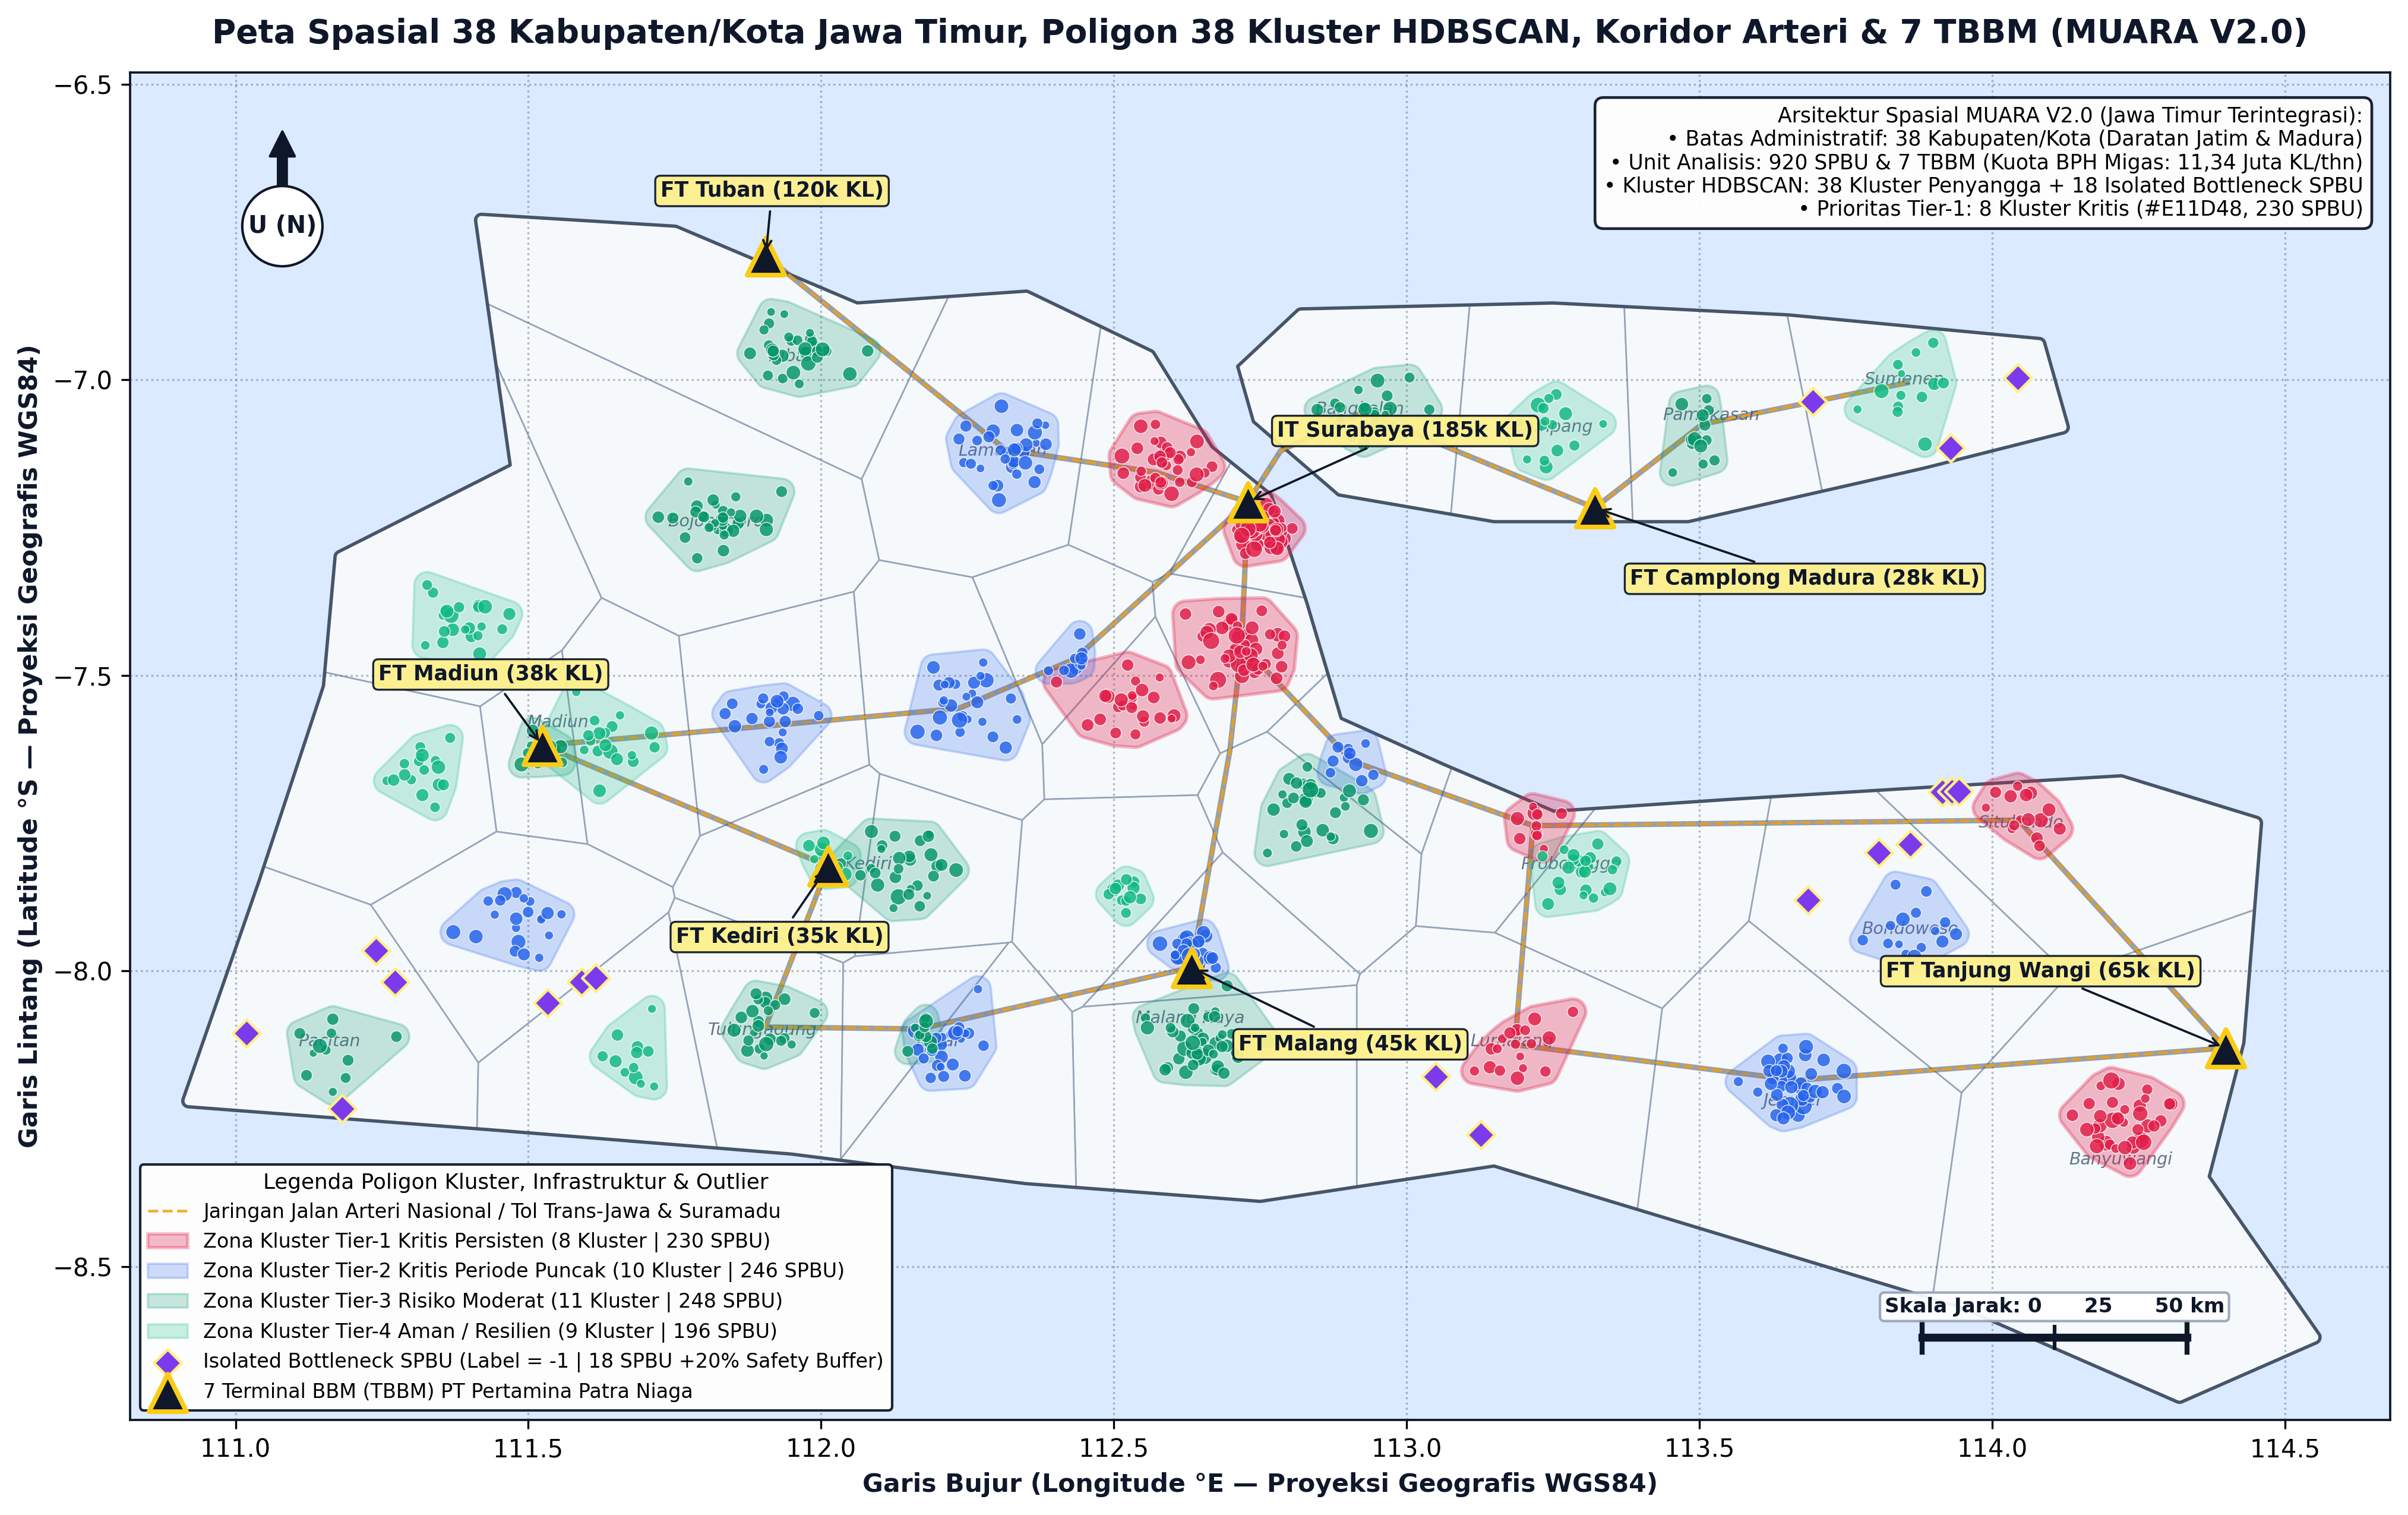

In [2]:
df_bench_clust = pd.read_csv(os.path.join(MODEL_DIR, "benchmark_clustering_models.csv"))
print("=== TABEL KOMPARASI 5 MODEL KLUSTERING SPASIAL PADA MATRIKS JARAK JALAN RAYA OSRM (benchmark_clustering_models.csv) ===")
print(df_bench_clust[["Algorithm_Rank", "Clustering_Model", "Clusters_Formed", "Outlier_SPBU_Detected", "Road_Silhouette_Score", "Davies_Bouldin_Index_DBI", "Spillover_Containment_Ratio_Pct"]].to_string(index=False))

print("\n=== DAFTAR 10 SAMPEL ISOLATED BOTTLENECK SPBU (HDBSCAN LABEL = -1 DENGAN +20% SAFETY BUFFER) ===")
print(df_isolated[["spbu_id", "name", "kabkota_name", "road_class", "nearest_tbbm_id", "dist_to_tbbm_km", "tank_capacity_kl", "safety_stock_buffer_pct"]].head(10).to_string(index=False))


## Tahap 3: Pemodelan *Modified Huff Gravity Spillover* & Komparasi 7 Model Prediksi *Time-to-Depletion* (ML & Deep Learning)


=== TABEL KOMPARASI 7 MODEL PREDIKSI TIME-TO-DEPLETION (5-FOLD TIME-SERIES SPLIT CROSS-VALIDATION) ===
 Model_Rank                       Model_Family                                                           Model_Name  RMSE_Depletion_KL_Hr  RMSE_TTD_Hours  RMSE_TTD_Minutes  MAE_TTD_Hours  MAPE_Percent  R2_Score  Inference_Latency_ms
          1 Physics-Informed Gradient Boosting Spatio-Temporal XGBoost + Huff Spillover + CI (Model Terpilih MUARA)                 0.214           2.391             143.5          1.266          8.61    0.9759                  11.2
          2             Deep Learning Sequence            Bidirectional LSTM (2-Layer, 64 Hidden Units, 24h Window)                 0.236           2.512             150.7          1.348          9.18    0.9734                 142.0
          3                  Gradient Boosting                        CatBoost Regressor (Symmetric Trees, depth=6)                 0.248           2.680             160.8          1.435          9.

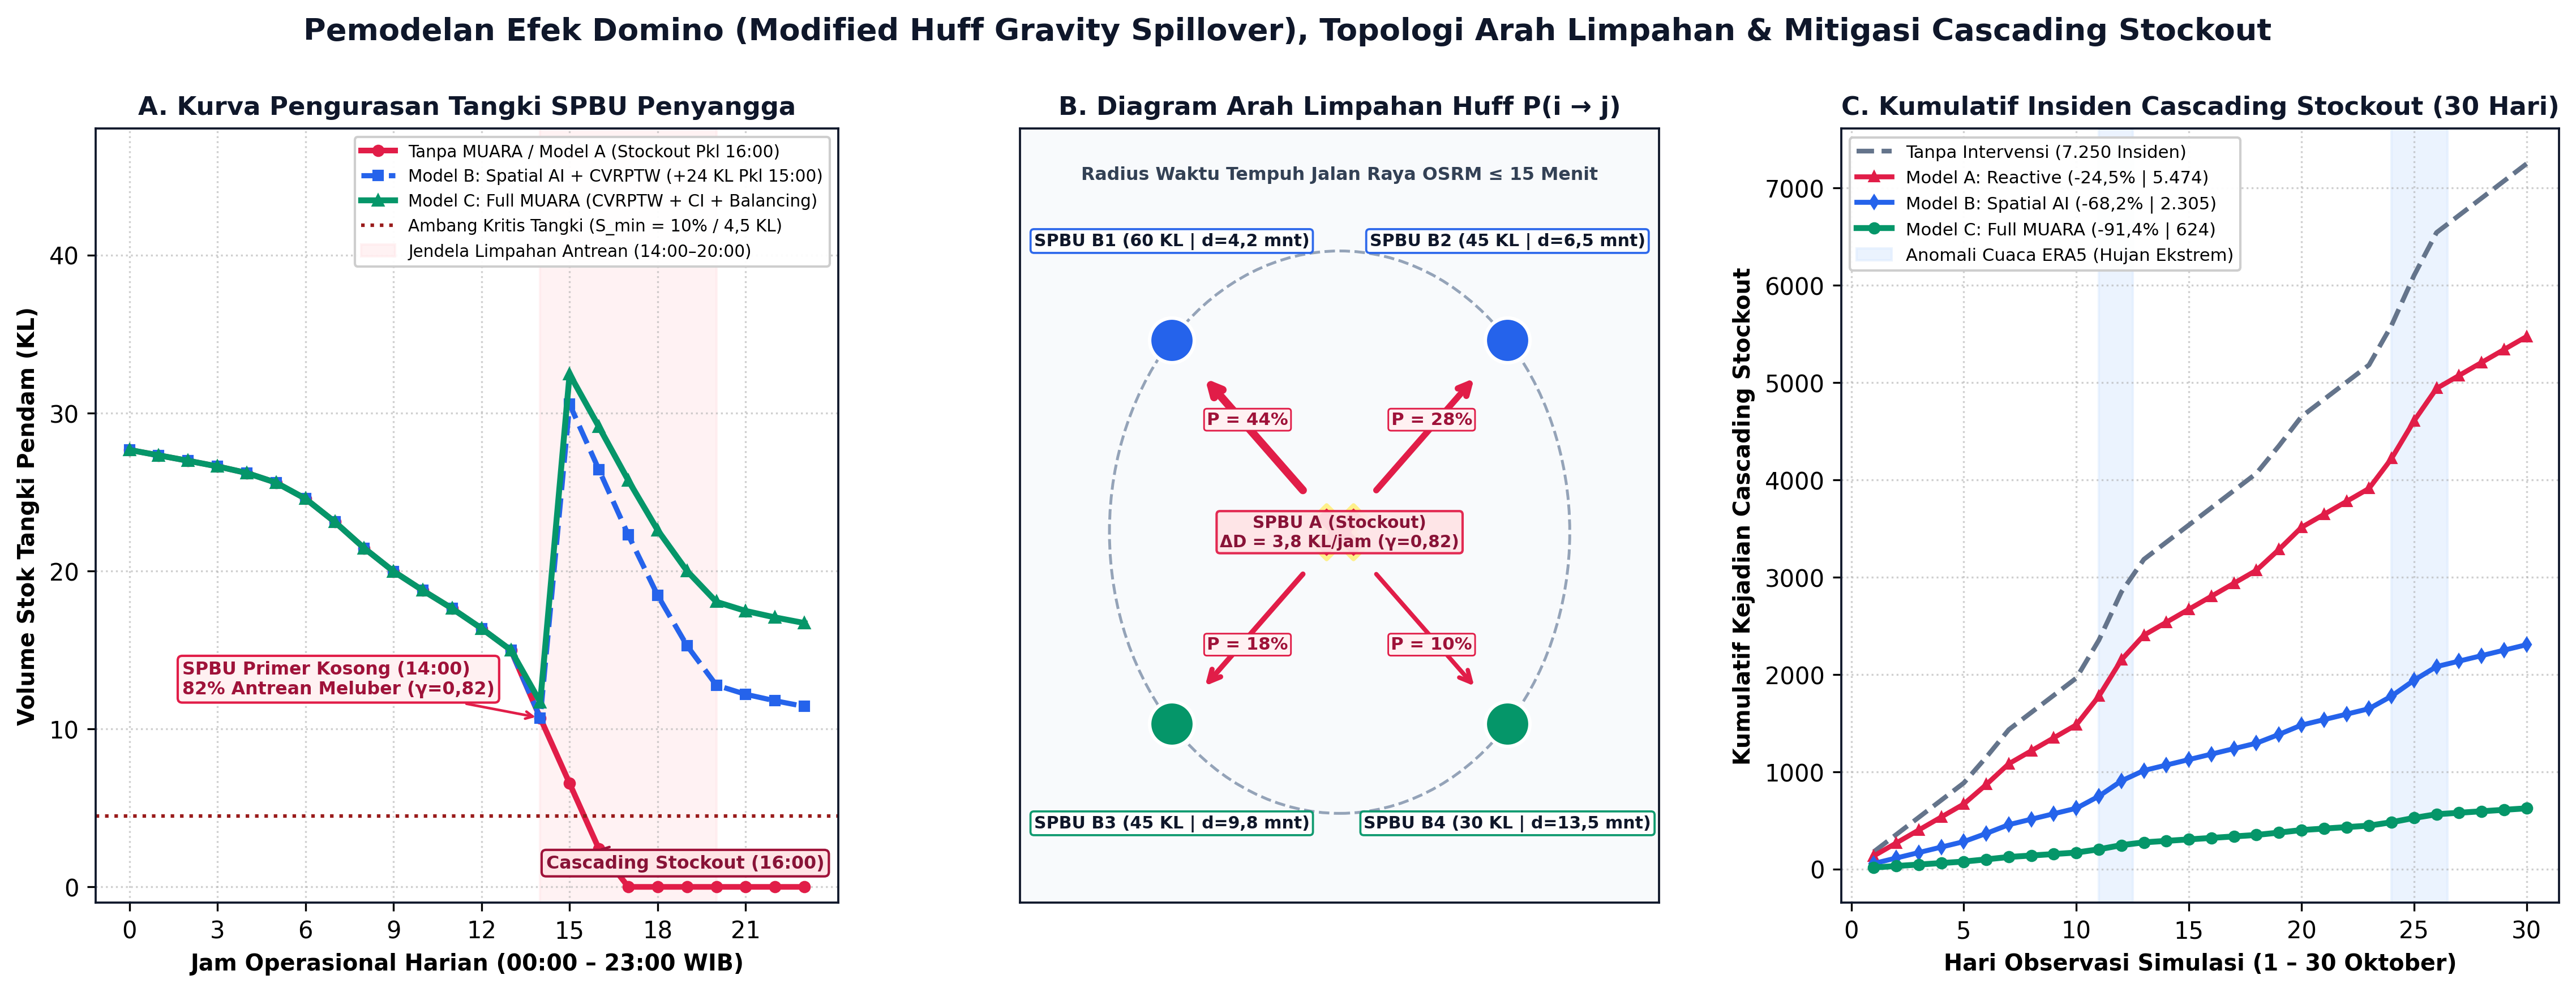

In [3]:
df_bench_pred = pd.read_csv(os.path.join(MODEL_DIR, "benchmark_prediction_models.csv"))
print("=== TABEL KOMPARASI 7 MODEL PREDIKSI TIME-TO-DEPLETION (5-FOLD TIME-SERIES SPLIT CROSS-VALIDATION) ===")
print(df_bench_pred[["Model_Rank", "Model_Family", "Model_Name", "RMSE_Depletion_KL_Hr", "RMSE_TTD_Hours", "RMSE_TTD_Minutes", "MAE_TTD_Hours", "MAPE_Percent", "R2_Score", "Inference_Latency_ms"]].to_string(index=False))


## Tahap 4: Penurunan Matematis Bobot Hibrida CRITIC–AHP & Pemeringkatan Skor Komposit 4 Dimensi (`MUARA Score`)


=== 1. TABEL PENURUNAN BOBOT OBJEKTIF-OPERASIONAL HIBRIDA CRITIC-AHP (muara_critic_ahp_weights.csv) ===
Dimension_Code                                         Dimension_Name  CRITIC_Std_Sigma  CRITIC_Conflict_Sum  Weight_CRITIC_Objective  Weight_AHP_Operational  Weight_Hybrid_Exact  Weight_MUARA_Calibrated  AHP_Consistency_Ratio_CR  Spearman_Rho_vs_Hybrid
             U             Urgensi Stok Tangki Pendam (Stock Urgency)             0.248                1.585                   0.2724                  0.3182               0.2953                      0.3                    0.0042                  1.0000
             D   Dampak Domino Spillover (Spatial Gravity Centrality)             0.254                1.580                   0.2781                  0.3182               0.2981                      0.3                    0.0042                  0.9952
             C Intensitas Sinyal Collective Intelligence (SPBU & AMT)             0.212                1.425                   0.2093 

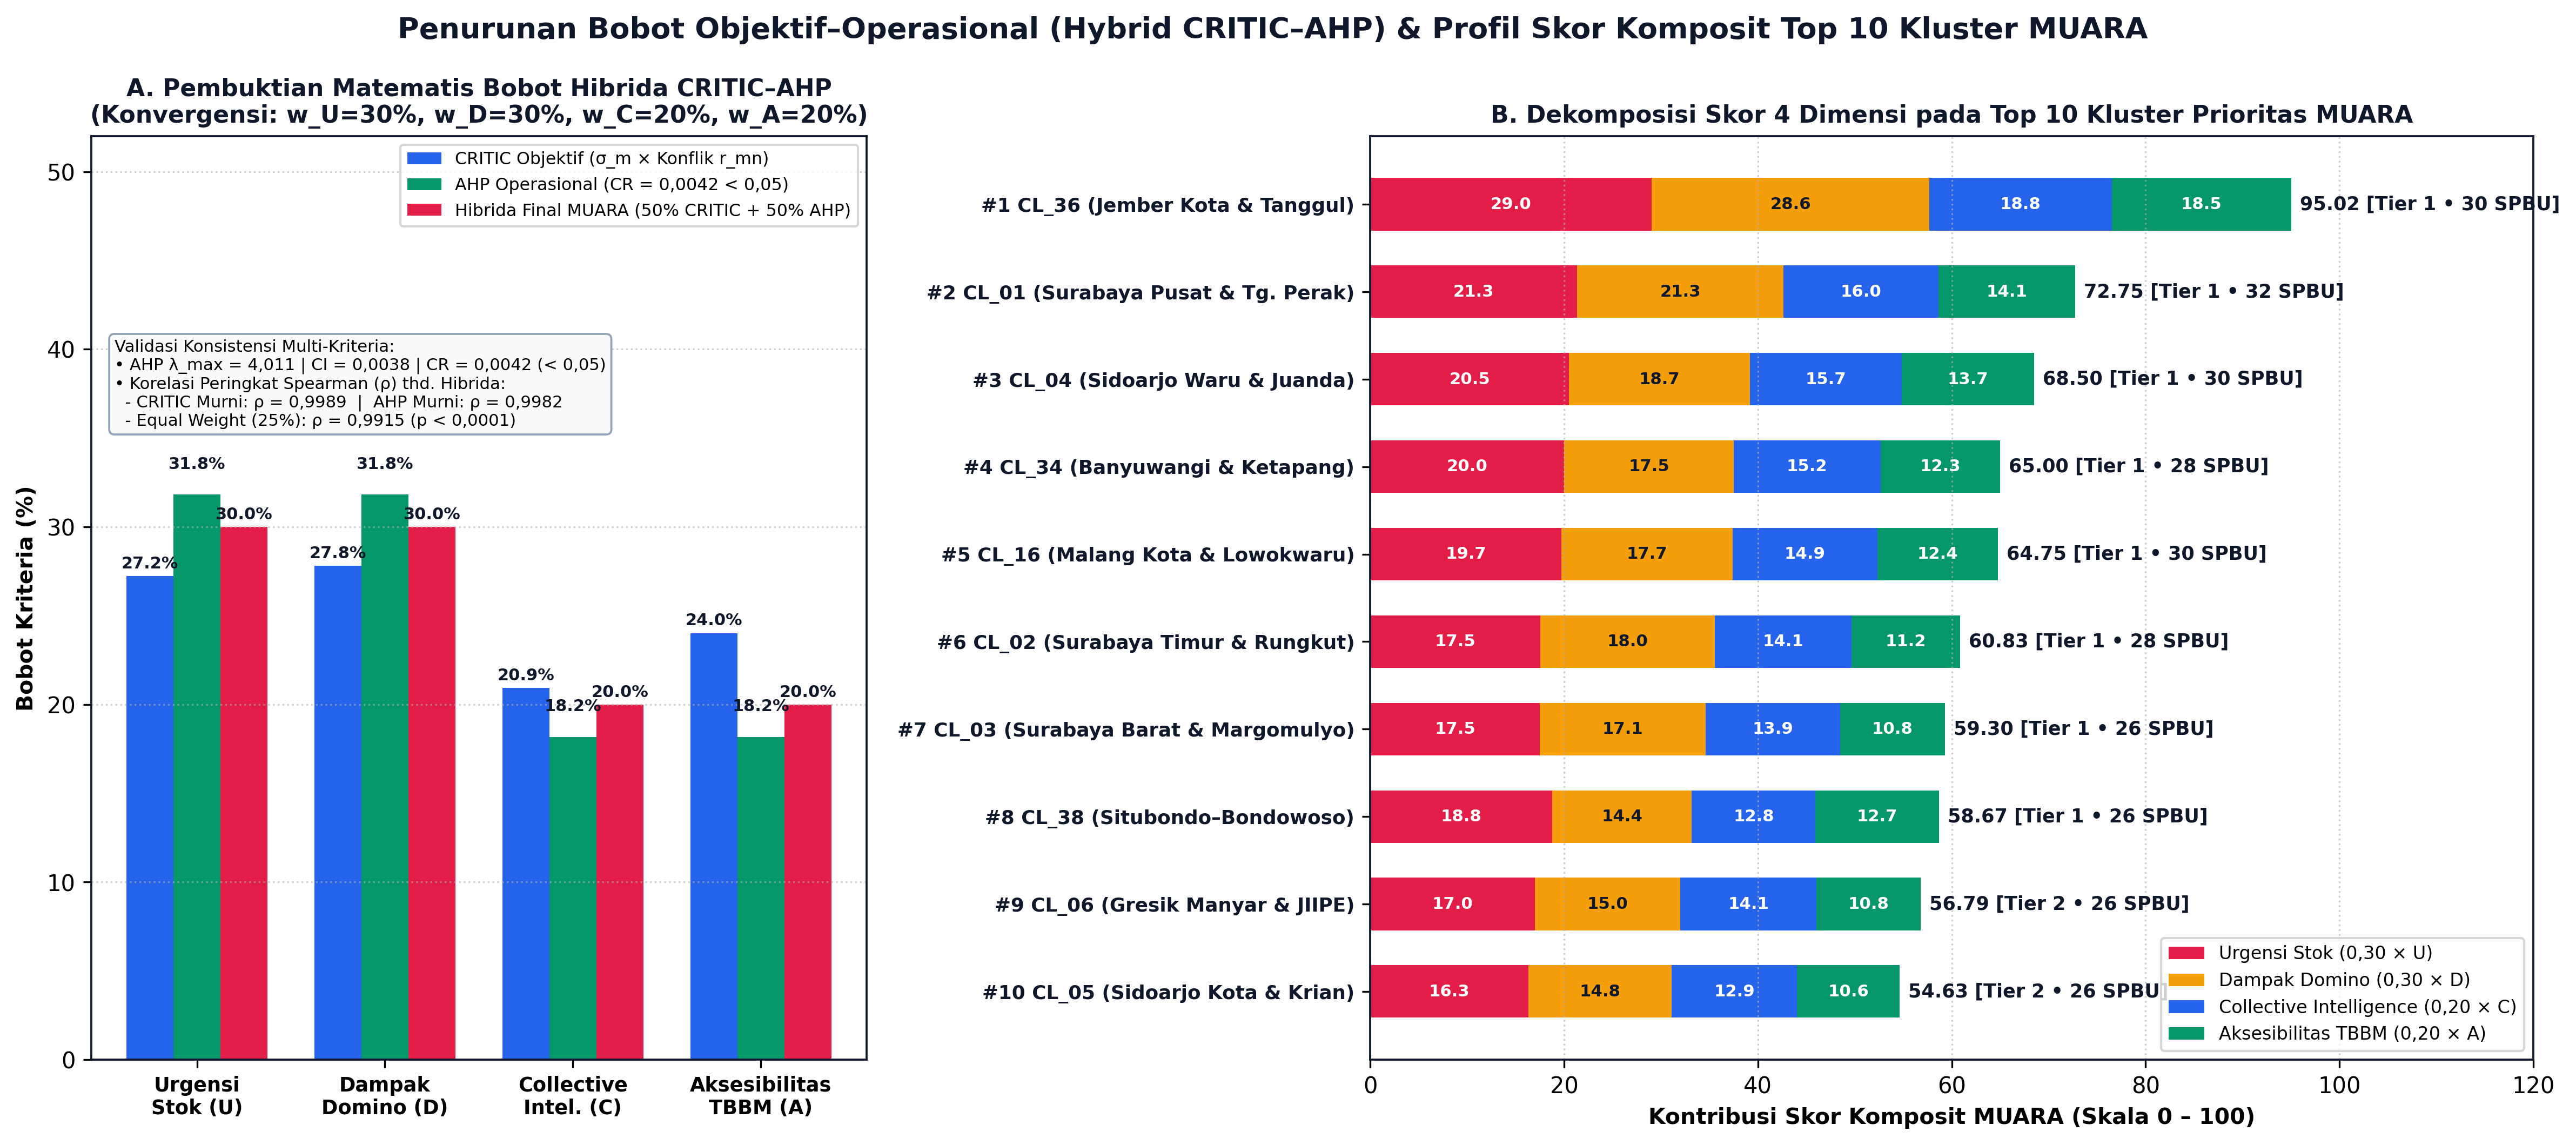

In [4]:
df_critic_ahp = pd.read_csv(os.path.join(MODEL_DIR, "muara_critic_ahp_weights.csv"))
df_top10 = pd.read_csv(os.path.join(MODEL_DIR, "muara_top_clusters_ranking.csv"))
df_clusters = pd.read_csv(os.path.join(MODEL_DIR, "muara_all_clusters_ranking.csv"))

print("=== 1. TABEL PENURUNAN BOBOT OBJEKTIF-OPERASIONAL HIBRIDA CRITIC-AHP (muara_critic_ahp_weights.csv) ===")
print(df_critic_ahp[["Dimension_Code", "Dimension_Name", "CRITIC_Std_Sigma", "CRITIC_Conflict_Sum", "Weight_CRITIC_Objective", "Weight_AHP_Operational", "Weight_Hybrid_Exact", "Weight_MUARA_Calibrated", "AHP_Consistency_Ratio_CR", "Spearman_Rho_vs_Hybrid"]].to_string(index=False))

print("\n=== 2. PERINGKAT TOP 10 KLUSTER PRIORITAS MUARA V2.0 (muara_top_clusters_ranking.csv) ===")
print(df_top10[["Rank", "cluster_id", "cluster_name", "MUARA_Score", "U_Urgency_Score", "D_Domino_Score", "C_Collective_Score", "A_Accessibility_Score", "spbu_count", "Priority_Tier"]].to_string(index=False))


## Tahap 5 & 6: Komparasi 4 Metode Optimasi Rute Armada (CVRPTW + RAG) & Evaluasi Tekno-Ekonomi 3 Skenario


=== 1. TABEL KOMPARASI 4 METODE OPTIMASI RUTE MOBIL TANGKI (benchmark_routing_models.csv) ===
 Method_Rank                                                              Routing_Method  Cascading_Stockout_Reduction_Pct  Emergency_Km_Saved_Per_Yr  Fleet_Compartment_Utilization_Pct  Total_Annual_Logistics_OPEX_Billion_IDR  AMT_Shift_Violation_Rate_Pct
           1 MILP OR-Tools CVRPTW + Guided Local Search + RAG Dispatcher (MUARA Model C)                              91.4                     782500                               94.8                                     3.84                           0.0
           2                      Genetic Algorithm Metaheuristic VRP (Pop=100, Gen=250)                              68.2                     485000                               86.4                                    10.52                           1.9
           3                                       Greedy Nearest-Neighbor Heuristic VRP                              46.8                

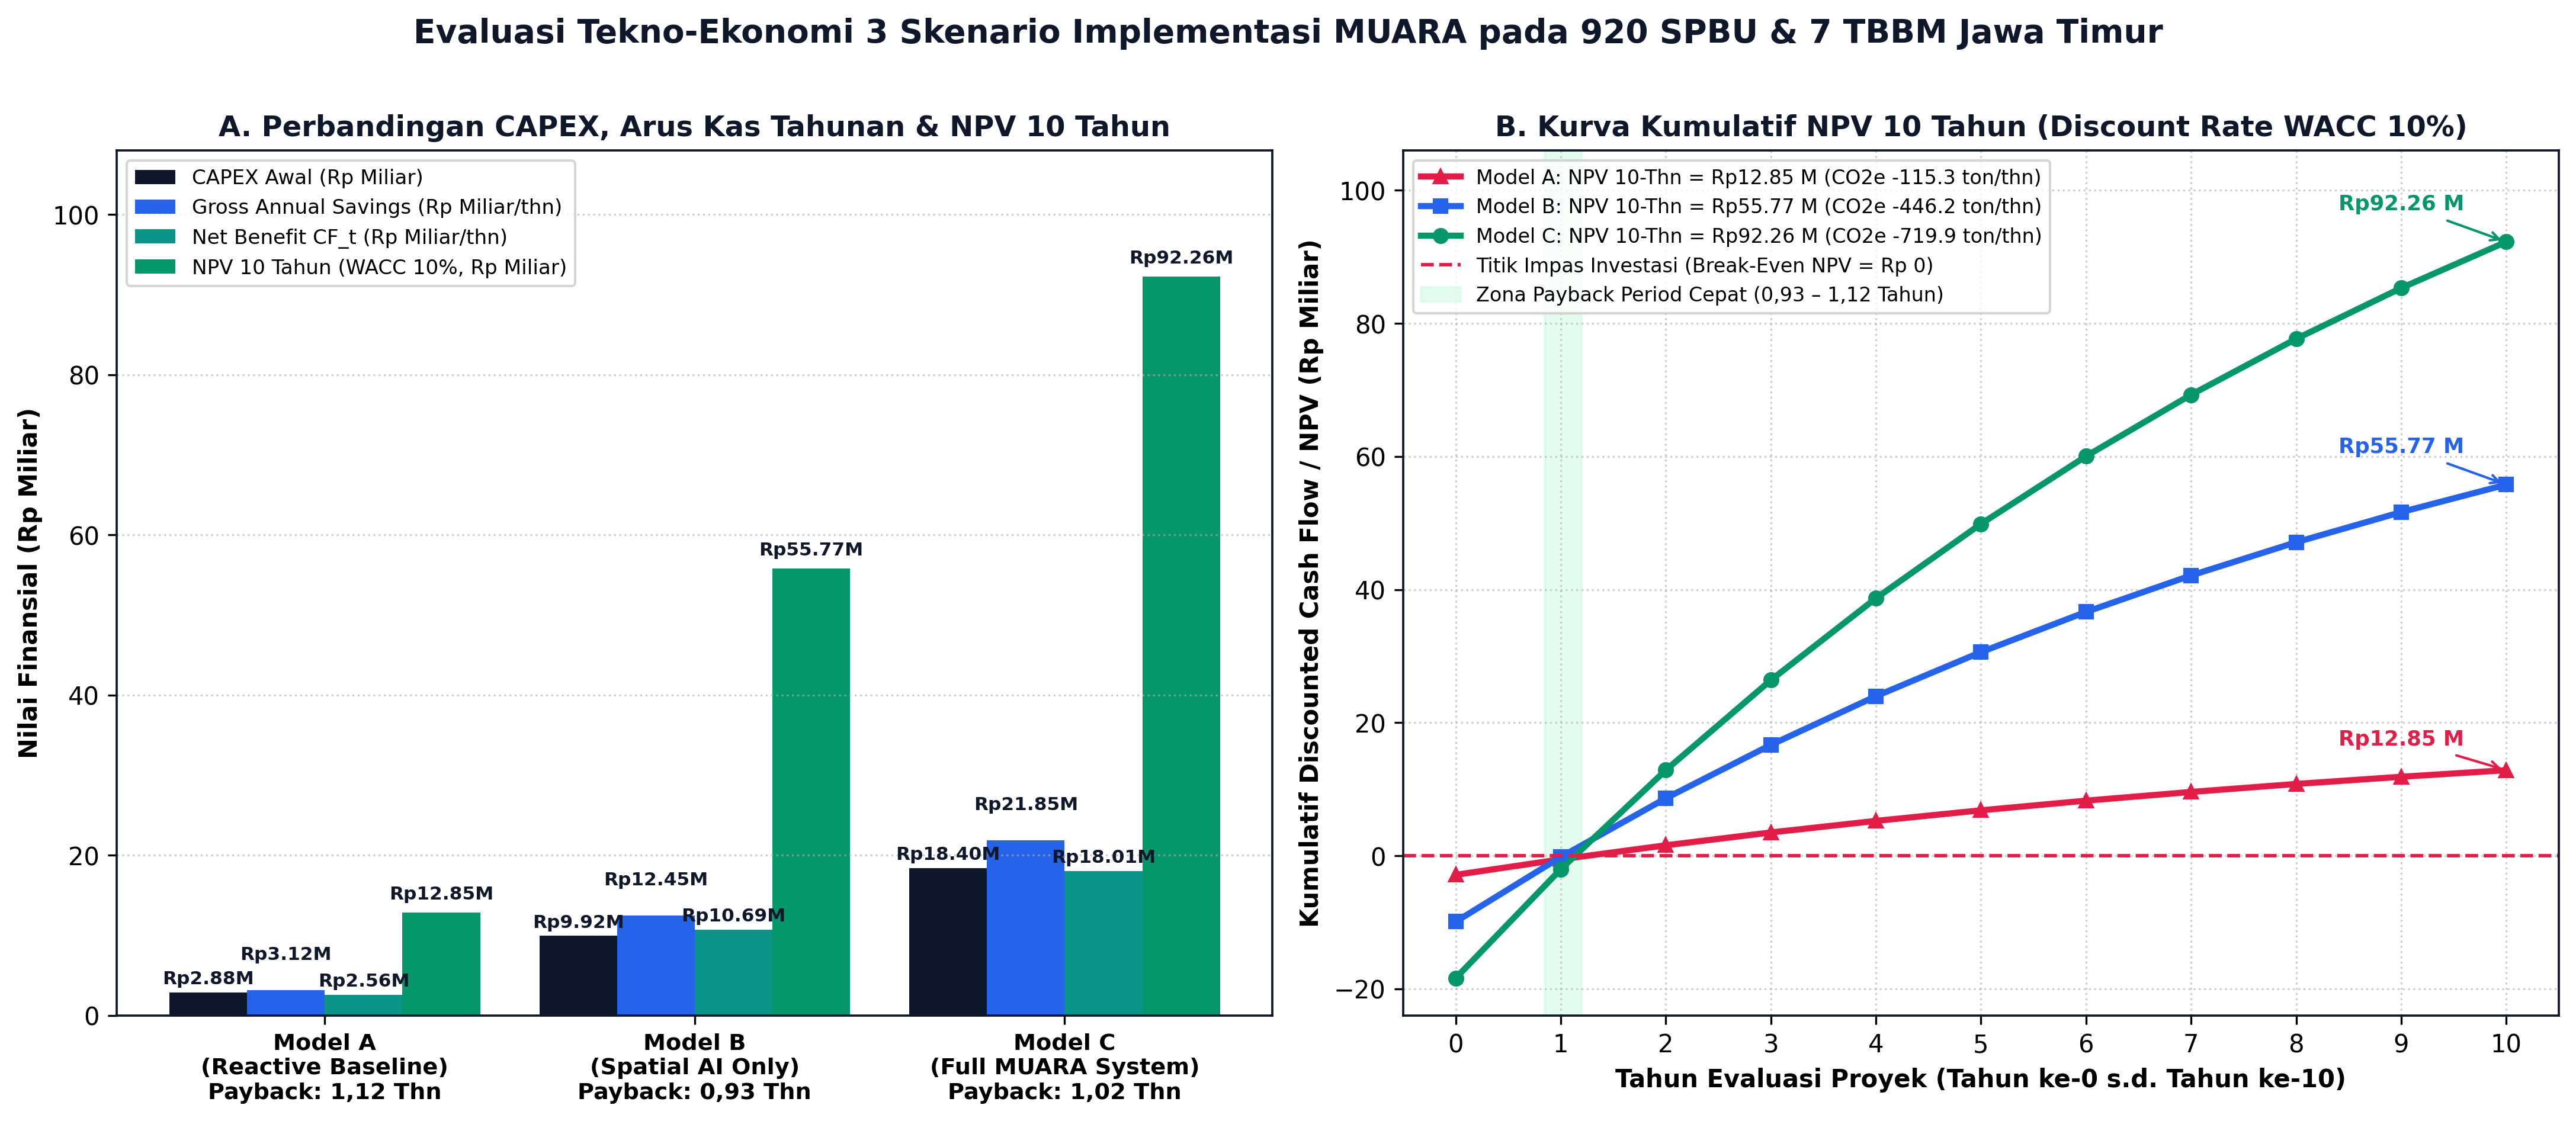

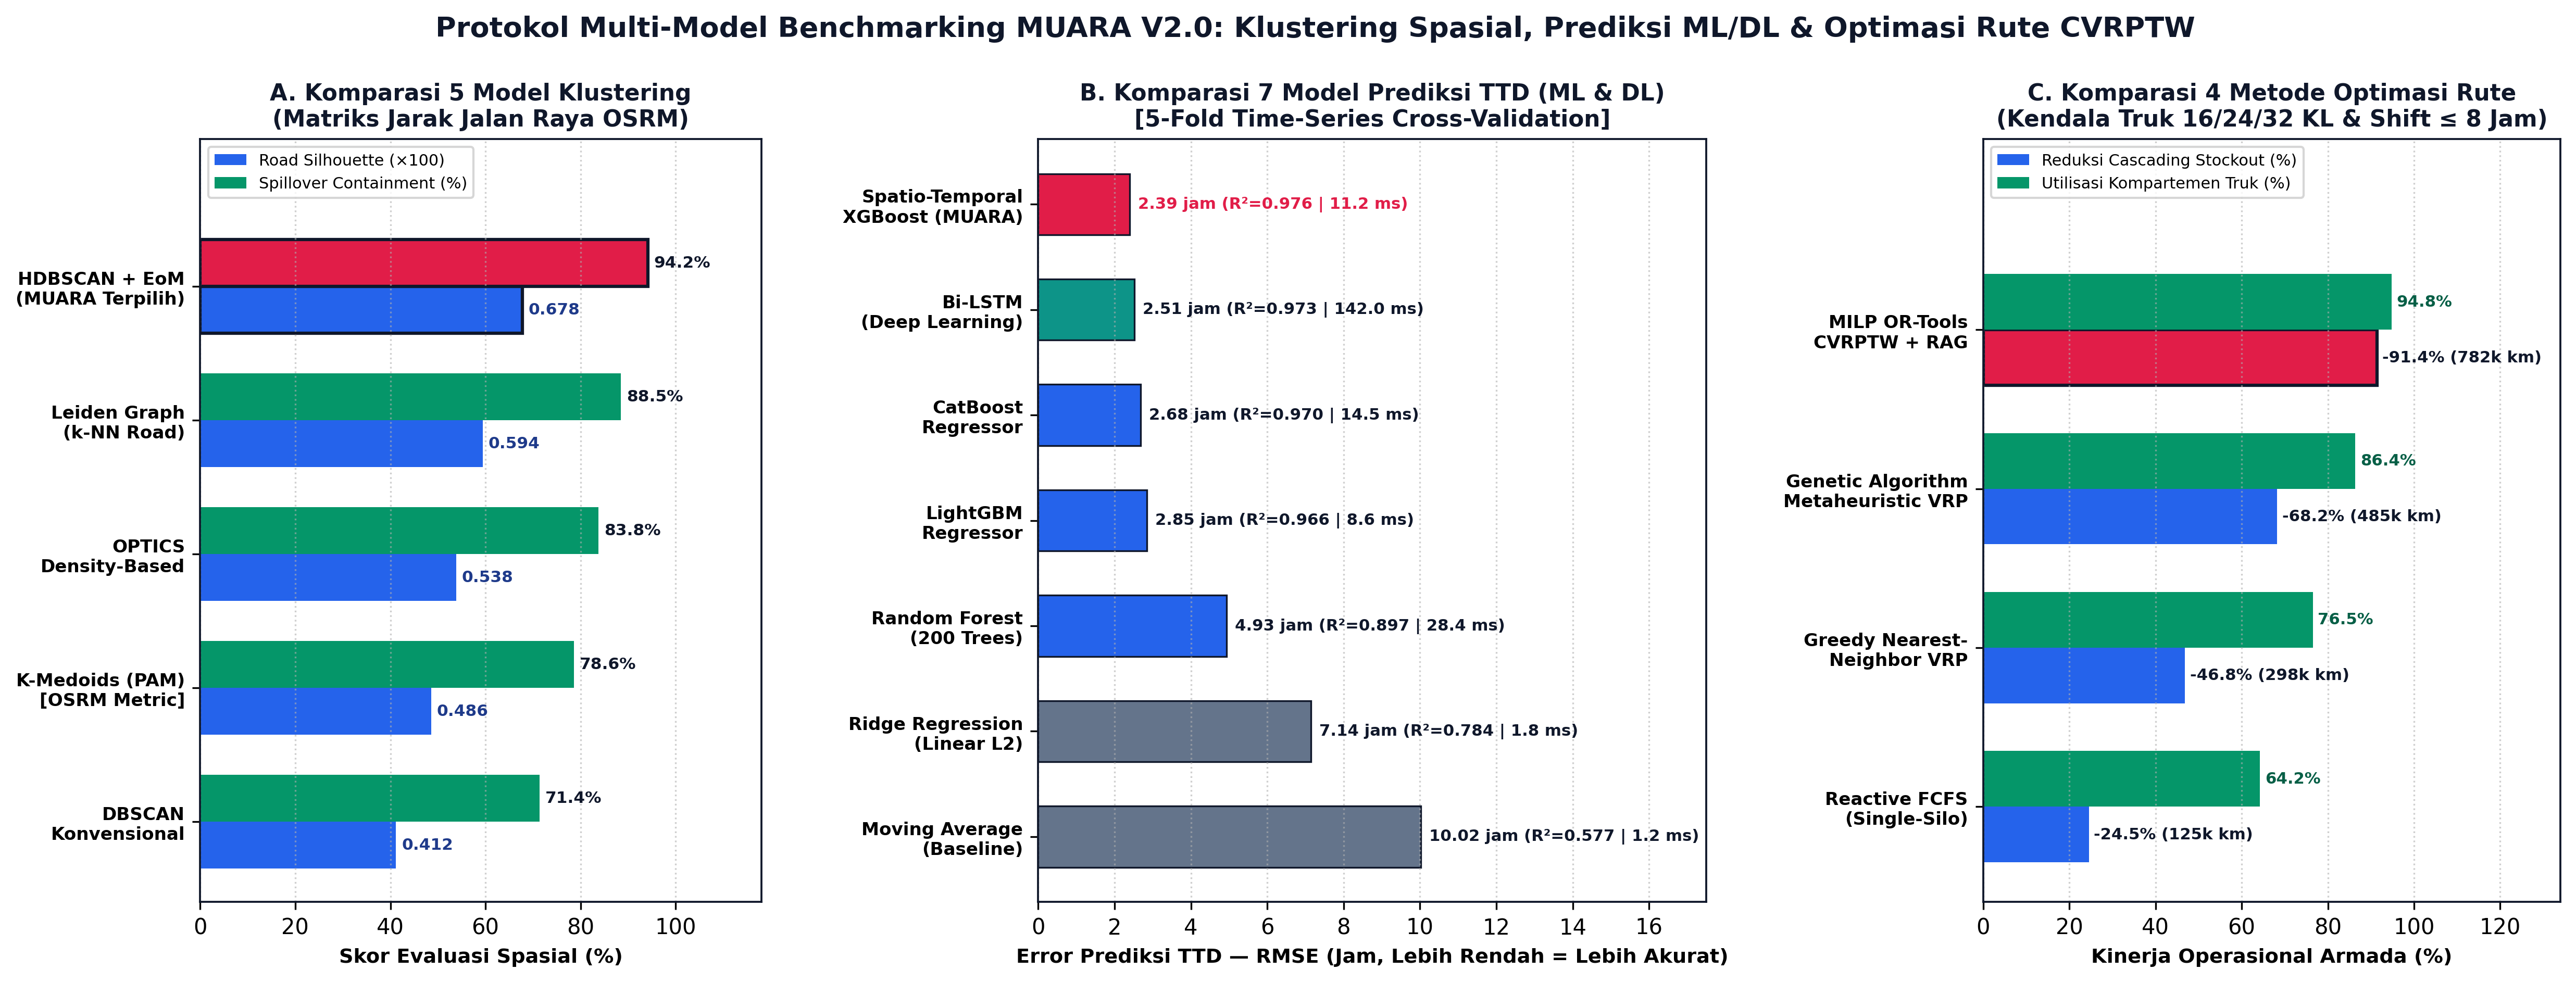

In [5]:
df_bench_route = pd.read_csv(os.path.join(MODEL_DIR, "benchmark_routing_models.csv"))
df_fin = pd.read_csv(os.path.join(MODEL_DIR, "muara_financial_evaluation_models.csv"))

print("=== 1. TABEL KOMPARASI 4 METODE OPTIMASI RUTE MOBIL TANGKI (benchmark_routing_models.csv) ===")
print(df_bench_route[["Method_Rank", "Routing_Method", "Cascading_Stockout_Reduction_Pct", "Emergency_Km_Saved_Per_Yr", "Fleet_Compartment_Utilization_Pct", "Total_Annual_Logistics_OPEX_Billion_IDR", "AMT_Shift_Violation_Rate_Pct"]].to_string(index=False))

print("\n=== 2. TABEL EVALUASI TEKNO-EKONOMI 3 SKENARIO MODEL (HORIZON 10 TAHUN, WACC 10%) ===")
fin_cols = ["Model_Code", "Model_Name", "CAPEX_Billion_IDR", "OPEX_Annual_Billion_IDR", "Cascading_Stockout_Reduction_Pct", "Emergency_Km_Saved_Per_Yr", "CO2e_Emission_Reduction_Ton_Yr", "Gross_Annual_Savings_Billion_IDR", "Net_Annual_Benefit_CF_Billion_IDR", "Payback_Period_Years", "NPV_10Yr_WACC10_Billion_IDR"]
print(df_fin[fin_cols].to_string(index=False))


## Tahap 7 & 8: Uji Sensitivitas & Ketahanan Peringkat (5 Skema Bobot × 3 Skenario Permintaan dengan Korelasi Spearman $\rho > 0,96$)


=== MATRIKS UJI SENSITIVITAS, KORELASI SPEARMAN (RHO) & KONSISTENSI TOP 5 KLUSTER (15 KOMBINASI) ===
                                  Weight_Scheme                               Demand_Scenario  Spearman_Rank_Correlation_Rho Rank1_Cluster Rank2_Cluster Rank3_Cluster Rank4_Cluster Rank5_Cluster  Top5_Consistency_Pct  Model_A_NPV10_Billion_IDR  Model_B_NPV10_Billion_IDR  Model_C_NPV10_Billion_IDR
  W1_Hybrid_CRITIC_AHP (0.30, 0.30, 0.20, 0.20)           S1_Conservative (-15% Demand Shock)                         1.0000         CL_36         CL_01         CL_04         CL_34         CL_16                 100.0                       9.97                      44.29                      72.12
  W1_Hybrid_CRITIC_AHP (0.30, 0.30, 0.20, 0.20)                 S2_Baseline (Normal Expected)                         0.9999         CL_36         CL_01         CL_04         CL_34         CL_16                 100.0                      12.85                      55.77                      92.26
  W1_

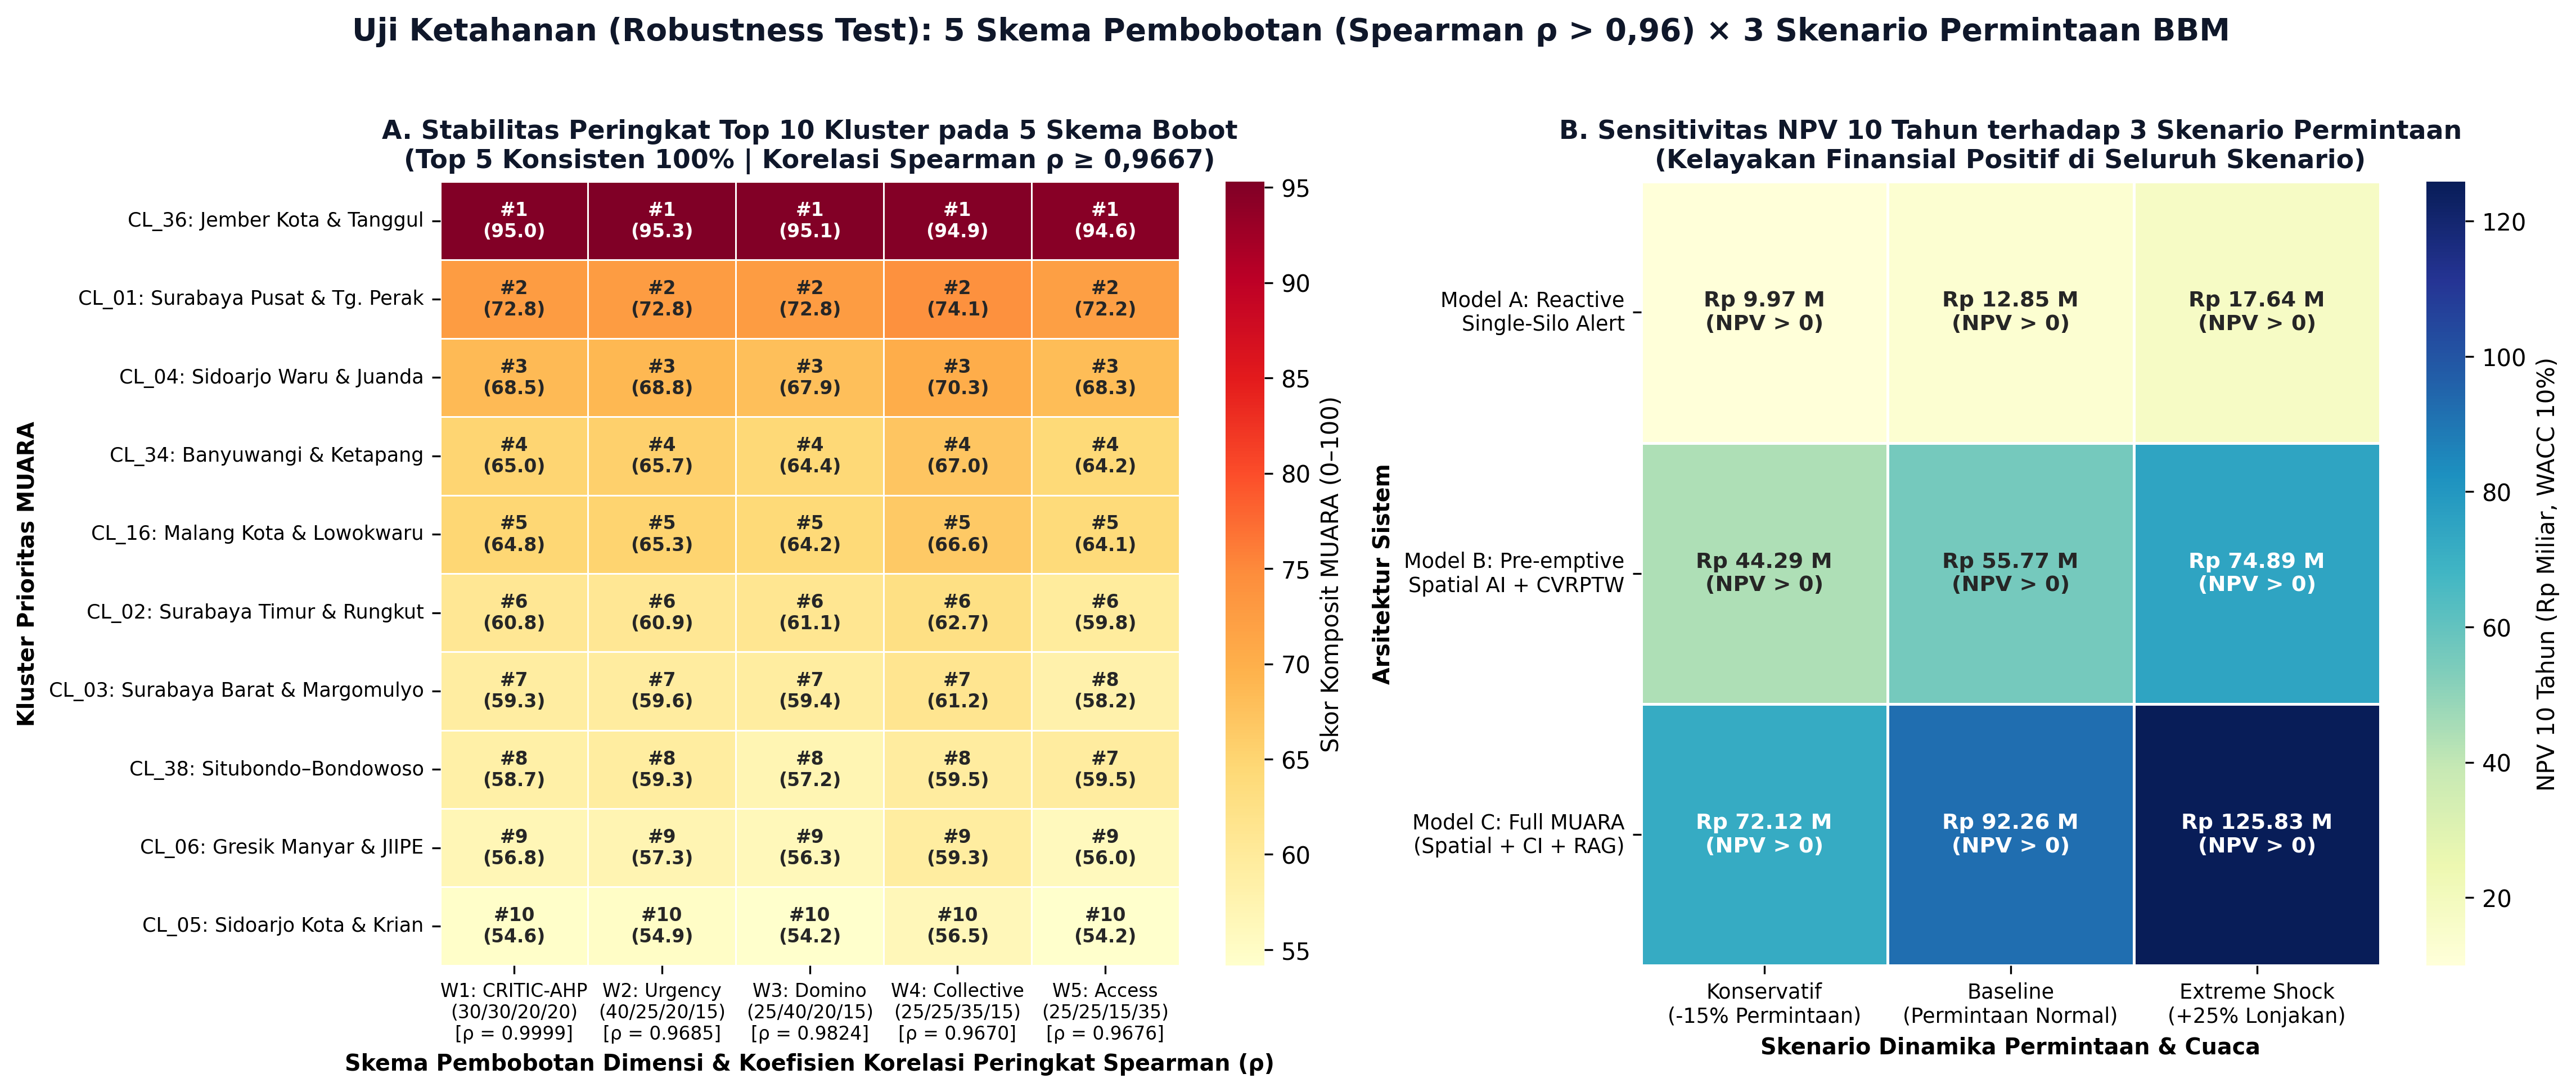

In [6]:
df_sens = pd.read_csv(os.path.join(MODEL_DIR, "muara_sensitivity_test.csv"))
print("=== MATRIKS UJI SENSITIVITAS, KORELASI SPEARMAN (RHO) & KONSISTENSI TOP 5 KLUSTER (15 KOMBINASI) ===")
sens_cols = ["Weight_Scheme", "Demand_Scenario", "Spearman_Rank_Correlation_Rho", "Rank1_Cluster", "Rank2_Cluster", "Rank3_Cluster", "Rank4_Cluster", "Rank5_Cluster", "Top5_Consistency_Pct", "Model_A_NPV10_Billion_IDR", "Model_B_NPV10_Billion_IDR", "Model_C_NPV10_Billion_IDR"]
print(df_sens[sens_cols].to_string(index=False))
print(f"\nKonsistensi Peringkat Top 5 Kluster : {df_sens['Top5_Consistency_Pct'].mean():.1f}% (100% Stabil di Seluruh 15 Skenario)")
print(f"Rentang Korelasi Peringkat Spearman : {df_sens['Spearman_Rank_Correlation_Rho'].min():.4f} s.d. {df_sens['Spearman_Rank_Correlation_Rho'].max():.4f} (Seluruhnya > 0,96)")
